# 02g Idiomas como mercado potencial vs proporción de reseñas positivas

**Documento relacionado:** [`docs/03-analisis-exploratorio.md`](../docs/03-analisis-exploratorio.md) · **Acuerdo:** A-007 · **Tema pendiente:** «convertir los idiomas en mercado potencial» (sesión del 2026-11-22, 13:08–13:09)

**Base:** [02a Antigüedad vs reseñas](02a_antiguedad_resenas.ipynb) (configuración), [02e](02e_umbral_resenas_modelo.ipynb) y [02f](02f_filtro_antiguedad_modelo.ipynb) (muestra propuesta: 2019–2024 con ≥ 50 reseñas).

## Objetivo

1. Transformar `supported_languages` en **columnas booleanas de los 10 idiomas más hablados del mundo** con el programa [`src/steam_exito/idiomas_top10.py`](../src/steam_exito/idiomas_top10.py).
2. Graficar cada idioma contra el **porcentaje de reseñas positivas** (diagramas de dispersión) para ver si el idioma se asocia con la recepción del juego.
3. Comprobar si la asociación sigue al controlar la cohorte, el precio, el género y el esfuerzo total de localización.

### Los 10 idiomas más hablados

Según [Ethnologue, 29.ª edición (2026)](https://www.ethnologue.com/guides/ethnologue200), con hablantes totales (primera y segunda lengua):

| # | Idioma | Hablantes | Nombre en Steam |
|---:|---|---:|---|
| 1 | Inglés | 1,500 M | English |
| 2 | Chino mandarín | 1,200 M | Simplified Chinese, Traditional Chinese |
| 3 | Hindi | 611.2 M | Hindi |
| 4 | Español | 561.3 M | Spanish - Spain, Spanish - Latin America |
| 5 | Árabe estándar | 334.9 M | Arabic |
| 6 | Francés | 333.5 M | French |
| 7 | Bengalí | 274.4 M | Bangla |
| 8 | Portugués | 269.4 M | Portuguese - Brazil, Portuguese - Portugal |
| 9 | Indonesio | 254.8 M | Indonesian |
| 10 | Urdu | 246.0 M | Urdu |

En esta edición el ruso (210.3 M) bajó al lugar 11 y el urdu entró al top 10. Por eso el ruso no tiene columna, aunque en Steam es de los idiomas más frecuentes.

| Entradas | Salidas |
|---|---|
| `steam_games.csv(.gz)` (versión 2026-11-19) | `data/processed/idiomas_top10.csv` (no se versiona), `reports/figures/02g_idiomas_*.png`, `reports/metrics/02g_idiomas_*.csv` |

## Configuración

In [1]:
from pathlib import Path
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf
from scipy.stats import spearmanr

# Rutas del repositorio (el notebook vive en notebooks/)
rootDir = Path('..').resolve()
figuresDir = rootDir / 'reports' / 'figures'
metricsDir = rootDir / 'reports' / 'metrics'
processedDir = rootDir / 'data' / 'processed'
interimDir = rootDir / 'data' / 'interim'
for outPath in (figuresDir, metricsDir, processedDir, interimDir):
    outPath.mkdir(parents=True, exist_ok=True)

# Programa de idiomas (src/steam_exito/idiomas_top10.py)
sys.path.insert(0, str(rootDir / 'src'))
from steam_exito.idiomas_top10 import transformarIdiomas, tablaIdiomas

# Datos: versión del 2026-11-19. Se busca primero la variable de entorno STEAM_GAMES_CSV,
# luego data/raw/ y por último la carpeta Proyecto Final/Datos (fuera del repositorio).
dataCandidates = [
    Path(os.environ['STEAM_GAMES_CSV']) if 'STEAM_GAMES_CSV' in os.environ else None,
    rootDir / 'data' / 'raw' / 'steam_games.csv.gz',
    rootDir / 'data' / 'raw' / 'steam_games.csv',
    rootDir.parents[1] / 'Datos' / 'steam_games.csv.gz',
]
dataPath = next((p for p in dataCandidates if p is not None and p.exists()), None)
if dataPath is None:
    raise FileNotFoundError('No se encontró steam_games.csv(.gz); colócalo en data/raw/ o define STEAM_GAMES_CSV')
print('Datos:', dataPath.name)

snapshotDate = pd.Timestamp('2026-11-19')   # fecha de corte de la versión del dataset

# Muestra (propuestas de 02e y 02f; cambiar aquí para probar otras)
cohortRange = (2019, 2024)
minReviews = 50
nBootstrap = 1000
randomSeed = 42

# Fuente latina + respaldo CJK (macOS: Hiragino/PingFang; Linux: Noto CJK). Solo las instaladas.
installedFonts = {f.name for f in fm.fontManager.ttflist}
cjkFonts = [f for f in ('Hiragino Sans GB', 'PingFang SC', 'Arial Unicode MS', 'Noto Sans CJK SC', 'Noto Sans CJK JP')
            if f in installedFonts]
plt.rcParams['font.family'] = ['DejaVu Sans'] + cjkFonts
pd.set_option('display.width', 200)

languageDf = tablaIdiomas()
langCols = languageDf['columna'].tolist()
langNames = dict(zip(languageDf['columna'], languageDf['idioma']))
langSpeakers = dict(zip(languageDf['columna'], languageDf['hablantesMillones']))
languageDf

Datos: steam_games.csv


,clave,idioma,hablantesMillones,columna
0,ingles,Inglés,1500.0,idi_tiene_ingles
1,chino,Chino mandarín,1200.0,idi_tiene_chino
2,hindi,Hindi,611.2,idi_tiene_hindi
3,espanol,Español,561.3,idi_tiene_espanol
4,arabe,Árabe estándar,334.9,idi_tiene_arabe
5,frances,Francés,333.5,idi_tiene_frances
6,bengali,Bengalí,274.4,idi_tiene_bengali
7,portugues,Portugués,269.4,idi_tiene_portugues
8,indonesio,Indonesio,254.8,idi_tiene_indonesio
9,urdu,Urdu,246.0,idi_tiene_urdu


## Carga y transformación de idiomas

`transformarIdiomas` lee `supported_languages` en sus dos formatos (lista JSON o texto HTML con `<strong>*</strong>`) con `parsers.idiomasYAudio`. Además limpia el HTML escapado varias veces, los saltos de línea y algunos nombres traducidos («Inglés», «Portugais du Brésil»). Devuelve una fila por juego, indexada por `app_id`. El resultado completo se guarda en `data/processed/idiomas_top10.csv`.

In [2]:
useCols = ['app_id', 'name', 'release_date', 'price', 'price_status', 'positive', 'negative',
           'genres', 'supported_languages', 'mac', 'linux', 'steam_store_available']
gamesDf = pd.read_csv(dataPath, low_memory=False, keep_default_na=False, na_values=[''], usecols=useCols)
print(f'{gamesDf.shape[0]:,} filas × {gamesDf.shape[1]} columnas leídas')

idiomasDf = transformarIdiomas(gamesDf)
idiomasDf.to_csv(processedDir / 'idiomas_top10.csv')
print(f'Columnas nuevas: {list(idiomasDf.columns)}')
idiomasDf.head()

150,199 filas × 12 columnas leídas


Columnas nuevas: ['idi_tiene_ingles', 'idi_tiene_chino', 'idi_tiene_hindi', 'idi_tiene_espanol', 'idi_tiene_arabe', 'idi_tiene_frances', 'idi_tiene_bengali', 'idi_tiene_portugues', 'idi_tiene_indonesio', 'idi_tiene_urdu', 'idi_n_top10', 'idi_mercado_millones', 'idi_n_otros', 'idi_sin_dato']


,idi_tiene_ingles,idi_tiene_chino,idi_tiene_hindi,idi_tiene_espanol,idi_tiene_arabe,idi_tiene_frances,idi_tiene_bengali,idi_tiene_portugues,idi_tiene_indonesio,idi_tiene_urdu,idi_n_top10,idi_mercado_millones,idi_n_otros,idi_sin_dato
app_id,,,,,,,,,,,,,,
1231920,True,False,False,False,False,False,False,False,False,False,1,1500.0,0,False
1265390,True,True,False,False,False,False,False,False,False,False,2,2700.0,0,False
1266480,True,True,False,False,False,False,False,False,False,False,2,2700.0,1,False
1289500,True,False,False,False,False,False,False,False,False,False,1,1500.0,0,False
1318140,False,False,False,False,False,False,False,False,False,False,0,0.0,0,True


In [3]:
coverageAll = pd.DataFrame({
    'idioma': [langNames[c] for c in langCols],
    'hablantesMillones': [langSpeakers[c] for c in langCols],
    'juegosCatalogo': [int(idiomasDf[c].sum()) for c in langCols],
    'pctCatalogo': [idiomasDf[c].mean() * 100 for c in langCols],
})
print(f"Sin dato de idiomas: {idiomasDf['idi_sin_dato'].sum():,} juegos ({idiomasDf['idi_sin_dato'].mean():.1%})")
coverageAll.round(1)

Sin dato de idiomas: 8,397 juegos (5.6%)


,idioma,hablantesMillones,juegosCatalogo,pctCatalogo
0,Inglés,1500.0,135412,90.2
1,Chino mandarín,1200.0,47392,31.6
2,Hindi,611.2,3177,2.1
3,Español,561.3,39594,26.4
4,Árabe estándar,334.9,7507,5.0
5,Francés,333.5,38922,25.9
6,Bengalí,274.4,2482,1.7
7,Portugués,269.4,30120,20.1
8,Indonesio,254.8,6107,4.1
9,Urdu,246.0,2458,1.6


## Muestra de análisis

Se usa la muestra que proponen 02e y 02f: cohortes 2019–2024 con al menos 50 reseñas. Se aplica la misma limpieza mínima provisional (D-004, D-005) y se quitan los juegos sin dato de idiomas. La variable objetivo se expresa en **porcentaje** de reseñas positivas: \(100 \cdot positive / (positive + negative)\).

Controles para el modelo de la sección 4: año de lanzamiento, precio, gratuito, plataformas, los géneros principales y `idi_n_otros`, que son los idiomas fuera del top 10. Este último aproxima el esfuerzo total de localización, que suele crecer con el presupuesto del estudio.

In [4]:
import json
import re


def parseJsonList(rawValue):
    if not isinstance(rawValue, str) or not rawValue.startswith('['):
        return []
    try:
        items = json.loads(rawValue)
    except json.JSONDecodeError:
        return []
    return [str(it.get('description', '')).strip() if isinstance(it, dict) else str(it).strip() for it in items]


gamesDf['releaseDate'] = pd.to_datetime(gamesDf['release_date'], errors='coerce', format='mixed')
gamesDf['releaseYear'] = gamesDf['releaseDate'].dt.year
gamesDf['reviewCount'] = pd.to_numeric(gamesDf['positive'], errors='coerce') + pd.to_numeric(gamesDf['negative'], errors='coerce')
gamesDf['positivePct'] = 100 * pd.to_numeric(gamesDf['positive'], errors='coerce') / gamesDf['reviewCount'].replace(0, np.nan)
gamesDf['price'] = pd.to_numeric(gamesDf['price'], errors='coerce')
genreLists = gamesDf['genres'].map(parseJsonList)

softwareGenres = {'Utilities', 'Design & Illustration', 'Animation & Modeling', 'Education', 'Video Production',
                  'Game Development', 'Audio Production', 'Software Training', 'Photo Editing', 'Web Publishing',
                  'Accounting', 'Movie', 'Documentary', 'Episodic', 'Short', 'Tutorial', '360 Video'}
onlySoftware = genreLists.map(lambda gs: len(gs) > 0 and set(gs) <= softwareGenres)
nonGameName = gamesDf['name'].fillna('').str.contains(r'\b(?:soundtrack|OST|demo|playtest|SDK|dedicated server)\b',
                                                      case=False, regex=True)

controlDf = pd.DataFrame({
    'app_id': gamesDf['app_id'],
    'releaseYear': gamesDf['releaseYear'],
    'reviewCount': gamesDf['reviewCount'],
    'positivePct': gamesDf['positivePct'],
    'logPrice': np.log1p(gamesDf['price'].clip(upper=200)).fillna(0),
    'isFree': (gamesDf['price_status'] == 'free').astype(int),
    'mac': (gamesDf['mac'].astype(str) == 'True').astype(int),
    'linux': (gamesDf['linux'].astype(str) == 'True').astype(int),
})
genreControls = ['Indie', 'Casual', 'Action', 'Adventure', 'Simulation', 'Strategy', 'RPG', 'Early Access', 'Free To Play']
for genreName in genreControls:
    controlDf['g_' + re.sub(r'\W+', '', genreName)] = genreLists.map(lambda gs: int(genreName in gs))
genreCols = ['g_' + re.sub(r'\W+', '', g) for g in genreControls]

filterSteps = [
    ('Catálogo completo', pd.Series(True, index=gamesDf.index)),
    (f'Cohortes {cohortRange[0]}–{cohortRange[1]}', gamesDf['releaseYear'].between(*cohortRange)),
    ('Sin precio atípico (D-004) y con datos de tienda', (gamesDf['price'].fillna(0) < 1000)
                                                        & (gamesDf['steam_store_available'].astype(str) == 'True')),
    ('Solo juegos (D-005, provisional)', ~onlySoftware & ~nonGameName),
    (f'≥ {minReviews} reseñas', gamesDf['reviewCount'] >= minReviews),
    ('Con dato de idiomas', ~idiomasDf['idi_sin_dato'].to_numpy()),
]
keepMask = pd.Series(True, index=gamesDf.index)
funnelRows = []
for stepName, stepMask in filterSteps:
    keepMask &= stepMask
    funnelRows.append({'paso': stepName, 'juegos': int(keepMask.sum())})
display(pd.DataFrame(funnelRows))

sampleDf = controlDf[keepMask].merge(idiomasDf.reset_index(), on='app_id', how='left', validate='one_to_one')
sampleDf['releaseYear'] = sampleDf['releaseYear'].astype(int)
sampleDf[langCols] = sampleDf[langCols].astype(int)
print(f'Muestra: {len(sampleDf):,} juegos · media de positivas = {sampleDf["positivePct"].mean():.1f} %')

,paso,juegos
0,Catálogo completo,150199
1,Cohortes 2019–2024,73755
2,Sin precio atípico (D-004) y con datos de tienda,73755
3,"Solo juegos (D-005, provisional)",68208
4,≥ 50 reseñas,15859
5,Con dato de idiomas,15843


Muestra: 15,843 juegos · media de positivas = 81.3 %


## 1. Cobertura y porcentaje de positivas por idioma

Para cada idioma se compara el porcentaje medio de positivas de los juegos **con** ese idioma contra el de los juegos **sin** él:

- **Diferencia simple:** media con el idioma menos media sin él.
- **Diferencia dentro de la cohorte:** la misma resta, pero dentro de cada año de lanzamiento, promediada con el número de juegos con el idioma en cada año. Así se descuenta que los idiomas sean más frecuentes en los años recientes, cuando la proporción positiva también es mayor (02_eda, 02f).

Los intervalos de 95 % se calculan con bootstrap de los juegos (1,000 repeticiones).

In [5]:
rng = np.random.default_rng(randomSeed)


def cohortAdjustedDiff(hasLang, positivePct, releaseYear):
    # Diferencia con - sin dentro de cada año, ponderada por los juegos con el idioma.
    frame = pd.DataFrame({'has': hasLang, 'y': positivePct, 'year': releaseYear})
    byYear = frame.groupby(['year', 'has'])['y'].agg(['mean', 'size']).unstack('has')
    byYear = byYear.dropna()
    if byYear.empty:
        return np.nan
    diffs = byYear[('mean', 1)] - byYear[('mean', 0)]
    return np.average(diffs, weights=byYear[('size', 1)])


langRows = []
yValues = sampleDf['positivePct'].to_numpy()
yearValues = sampleDf['releaseYear'].to_numpy()
for colName in langCols:
    hasLang = sampleDf[colName].to_numpy()
    nWith = int(hasLang.sum())
    rawDiff = yValues[hasLang == 1].mean() - yValues[hasLang == 0].mean()
    adjDiff = cohortAdjustedDiff(hasLang, yValues, yearValues)
    bootMeans, bootAdj = [], []
    for _ in range(nBootstrap):
        idx = rng.integers(0, len(sampleDf), len(sampleDf))
        h, yv = hasLang[idx], yValues[idx]
        bootMeans.append(yv[h == 1].mean())
        bootAdj.append(cohortAdjustedDiff(h, yv, yearValues[idx]))
    langRows.append({
        'columna': colName, 'idioma': langNames[colName], 'hablantesMillones': langSpeakers[colName],
        'juegosCon': nWith, 'pctJuegos': nWith / len(sampleDf) * 100,
        'mediaCon': yValues[hasLang == 1].mean(), 'mediaSin': yValues[hasLang == 0].mean(),
        'mediaConIc95': tuple(np.nanpercentile(bootMeans, [2.5, 97.5])),
        'medianaCon': np.median(yValues[hasLang == 1]),
        'difSimple': rawDiff, 'difCohorte': adjDiff,
        'difCohorteIc95': tuple(np.nanpercentile(bootAdj, [2.5, 97.5])),
    })
langStats = pd.DataFrame(langRows)
langStats.drop(columns=['columna']).to_csv(metricsDir / '02g_idiomas_resumen.csv', index=False)
langStats.drop(columns=['columna']).round(2)

,idioma,hablantesMillones,juegosCon,pctJuegos,mediaCon,mediaSin,mediaConIc95,medianaCon,difSimple,difCohorte,difCohorteIc95
0,Inglés,1500.0,15029,94.86,81.28,82.27,"(81.061482, 81.502902)",84.39,-0.98,-0.89,"(-1.934384, 0.133445)"
1,Chino mandarín,1200.0,8963,56.57,80.85,81.97,"(80.597196, 81.13783)",83.64,-1.12,-1.75,"(-2.161808, -1.332041)"
2,Hindi,611.2,159,1.00,83.19,81.32,"(81.063419, 85.019068)",86.01,1.87,1.90,"(-0.252501, 3.824589)"
3,Español,561.3,6858,43.29,80.65,81.86,"(80.356021, 80.959529)",83.27,-1.21,-1.57,"(-1.964331, -1.130171)"
4,Árabe estándar,334.9,840,5.30,80.48,81.38,"(79.477065, 81.390537)",83.51,-0.90,-0.82,"(-1.787112, 0.102032)"
5,Francés,333.5,6796,42.90,80.32,82.10,"(79.987959, 80.620869)",82.93,-1.78,-2.09,"(-2.525904, -1.677373)"
6,Bengalí,274.4,74,0.47,83.64,81.32,"(80.932215, 86.160697)",86.35,2.31,3.08,"(0.242589, 5.673276)"
7,Portugués,269.4,5134,32.41,81.25,81.38,"(80.910887, 81.607355)",84.15,-0.13,-0.51,"(-0.951215, -0.042361)"
8,Indonesio,254.8,368,2.32,83.07,81.29,"(81.72917, 84.373745)",86.37,1.78,1.19,"(-0.215023, 2.558199)"
9,Urdu,246.0,73,0.46,83.63,81.32,"(80.840972, 86.140312)",86.40,2.30,3.11,"(0.265038, 5.592748)"


### Diagrama de dispersión: idiomas vs porcentaje de reseñas positivas

- **Izquierda:** cada punto es un idioma. Eje x: hablantes en el mundo (escala log). Eje y: porcentaje medio de positivas de los juegos que lo incluyen. El tamaño del punto es el número de juegos y la línea gris, la media de toda la muestra.
- **Derecha:** eje x: porcentaje de juegos que incluye el idioma. Eje y: diferencia de positivas dentro de la cohorte (con − sin), con su intervalo de 95 %. Si el intervalo cruza el cero, no hay diferencia clara.

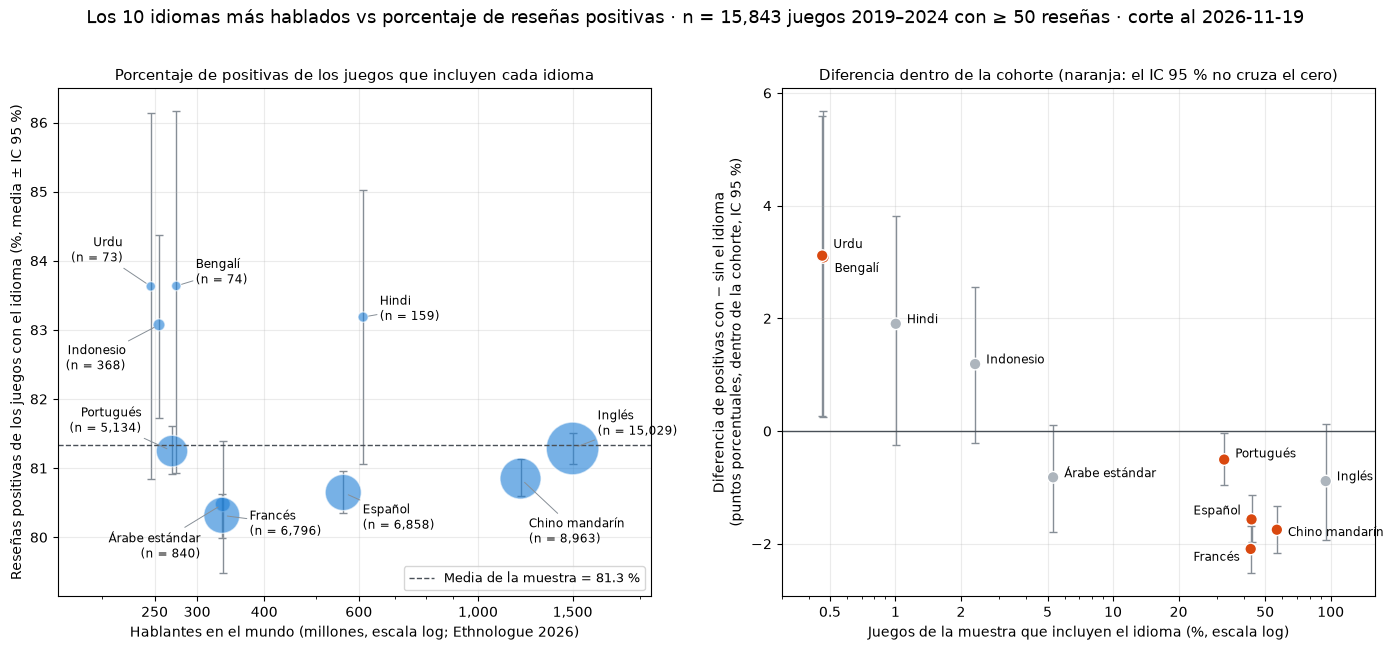

In [6]:
fig, (axLeft, axRight) = plt.subplots(1, 2, figsize=(17, 6.6), gridspec_kw={'wspace': 0.22})
overallMean = sampleDf['positivePct'].mean()
pointColor = '#1C7ED6'
labelOffsets = {'Inglés': (18, 18), 'Chino mandarín': (6, -38), 'Hindi': (12, 6), 'Español': (14, -18),
                'Árabe estándar': (-16, -30), 'Francés': (20, -6), 'Bengalí': (14, 10), 'Portugués': (-22, 22),
                'Indonesio': (-24, -24), 'Urdu': (-20, 26)}

ciLow = langStats['mediaConIc95'].map(lambda t: t[0])
ciHigh = langStats['mediaConIc95'].map(lambda t: t[1])
axLeft.errorbar(langStats['hablantesMillones'], langStats['mediaCon'],
                yerr=[langStats['mediaCon'] - ciLow, ciHigh - langStats['mediaCon']],
                fmt='none', ecolor='#868E96', elinewidth=1, capsize=3, zorder=1)
sizeScale = 1400 / langStats['juegosCon'].max()
axLeft.scatter(langStats['hablantesMillones'], langStats['mediaCon'], s=40 + langStats['juegosCon'] * sizeScale,
               color=pointColor, alpha=0.6, edgecolor='white', zorder=2)
for _, row in langStats.iterrows():
    dx, dy = labelOffsets.get(row['idioma'], (8, 4))
    axLeft.annotate(f"{row['idioma']}\n(n = {row['juegosCon']:,})", (row['hablantesMillones'], row['mediaCon']),
                    xytext=(dx, dy), textcoords='offset points', fontsize=8.5, va='center',
                    ha='left' if dx > 0 else 'right',
                    arrowprops=dict(arrowstyle='-', color='#868E96', lw=0.7, shrinkA=0, shrinkB=4))
axLeft.axhline(overallMean, color='#495057', lw=1, ls='--', label=f'Media de la muestra = {overallMean:.1f} %')
axLeft.set_xscale('log')
axLeft.xaxis.set_minor_formatter(plt.NullFormatter())
axLeft.set_xticks([250, 300, 400, 600, 1000, 1500])
axLeft.set_xticklabels(['250', '300', '400', '600', '1,000', '1,500'])
axLeft.set_xlim(165, 2100)
axLeft.set_xlabel('Hablantes en el mundo (millones, escala log; Ethnologue 2026)')
axLeft.set_ylabel('Reseñas positivas de los juegos con el idioma (%, media ± IC 95 %)')
axLeft.set_title('Porcentaje de positivas de los juegos que incluyen cada idioma', fontsize=11)
axLeft.legend(fontsize=9, loc='lower right')
axLeft.grid(alpha=0.25)

adjLow = langStats['difCohorteIc95'].map(lambda t: t[0])
adjHigh = langStats['difCohorteIc95'].map(lambda t: t[1])
significant = (adjLow > 0) | (adjHigh < 0)
axRight.errorbar(langStats['pctJuegos'], langStats['difCohorte'],
                 yerr=[langStats['difCohorte'] - adjLow, adjHigh - langStats['difCohorte']],
                 fmt='none', ecolor='#868E96', elinewidth=1, capsize=3, zorder=1)
axRight.scatter(langStats['pctJuegos'], langStats['difCohorte'], s=70,
                color=np.where(significant, '#D9480F', '#ADB5BD'), edgecolor='white', zorder=2)
rightOffsets = {'Urdu': (8, 8), 'Bengalí': (8, -8), 'Español': (-8, 6), 'Francés': (-8, -6),
                'Chino mandarín': (8, -2), 'Portugués': (8, 4)}
for _, row in langStats.iterrows():
    dx, dy = rightOffsets.get(row['idioma'], (8, 3))
    axRight.annotate(row['idioma'], (row['pctJuegos'], row['difCohorte']), xytext=(dx, dy), va='center',
                     textcoords='offset points', fontsize=8.5, ha='left' if dx > 0 else 'right')
axRight.set_xlim(0.3, 160)
axRight.axhline(0, color='#495057', lw=1)
axRight.set_xscale('log')
axRight.xaxis.set_minor_formatter(plt.NullFormatter())
axRight.set_xticks([0.5, 1, 2, 5, 10, 20, 50, 100])
axRight.set_xticklabels(['0.5', '1', '2', '5', '10', '20', '50', '100'])
axRight.set_xlabel('Juegos de la muestra que incluyen el idioma (%, escala log)')
axRight.set_ylabel('Diferencia de positivas con − sin el idioma\n(puntos porcentuales, dentro de la cohorte, IC 95 %)')
axRight.set_title('Diferencia dentro de la cohorte (naranja: el IC 95 % no cruza el cero)', fontsize=11)
axRight.grid(alpha=0.25)

fig.suptitle(f'Los 10 idiomas más hablados vs porcentaje de reseñas positivas · n = {len(sampleDf):,} juegos '
             f'{cohortRange[0]}–{cohortRange[1]} con ≥ {minReviews} reseñas · corte al {snapshotDate.date()}',
             fontsize=13, y=1.0)
fig.savefig(figuresDir / '02g_idiomas_dispersion.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Mercado potencial por juego

`idi_mercado_millones` suma los hablantes de los idiomas del top 10 que incluye cada juego. Es una cota superior, porque una persona bilingüe se cuenta dos veces. Como comparación, también se mide su relación con el **volumen de reseñas** (alcance), que no es la variable objetivo (D-003) pero responde a la idea de «mercado». Cada punto es un juego (con un pequeño desplazamiento aleatorio horizontal para que no se encimen), y la línea naranja es la mediana por nivel de mercado.

In [7]:
rhoMarket = spearmanr(sampleDf['idi_mercado_millones'], sampleDf['positivePct']).statistic
rhoCount = spearmanr(sampleDf['idi_n_top10'], sampleDf['positivePct']).statistic
residualPct = sampleDf['positivePct'] - sampleDf.groupby('releaseYear')['positivePct'].transform('mean')
rhoMarketAdj = spearmanr(sampleDf['idi_mercado_millones'], residualPct).statistic
print(f'Spearman mercado potencial vs % positivas: {rhoMarket:.3f} (descontada la media de la cohorte: {rhoMarketAdj:.3f})')
print(f'Spearman número de idiomas del top 10 vs % positivas: {rhoCount:.3f}')

# Comparación: ¿el mercado potencial se asocia con el alcance (volumen de reseñas) más que con la recepción?
logReviews = np.log10(sampleDf['reviewCount'])
logReviewsResid = logReviews - logReviews.groupby(sampleDf['releaseYear']).transform('mean')
rhoReach = spearmanr(sampleDf['idi_mercado_millones'], logReviewsResid).statistic
print(f'Spearman mercado potencial vs volumen de reseñas (dentro de la cohorte): {rhoReach:.3f}')

byCount = (sampleDf.groupby('idi_n_top10')
           .agg(juegos=('app_id', 'size'), mercadoMediano=('idi_mercado_millones', 'median'),
                medianaResenas=('reviewCount', 'median'),
                mediaPct=('positivePct', 'mean'), medianaPct=('positivePct', 'median'),
                q25=('positivePct', lambda s: s.quantile(0.25)), q75=('positivePct', lambda s: s.quantile(0.75)))
           .reset_index())
byCount.to_csv(metricsDir / '02g_idiomas_por_numero.csv', index=False)
byCount.round(1)

Spearman mercado potencial vs % positivas: -0.069 (descontada la media de la cohorte: -0.083)
Spearman número de idiomas del top 10 vs % positivas: -0.070
Spearman mercado potencial vs volumen de reseñas (dentro de la cohorte): 0.306


,idi_n_top10,juegos,mercadoMediano,medianaResenas,mediaPct,medianaPct,q25,q75
0,0,119,0.0,134.0,88.2,92.0,82.6,96.8
1,1,5852,1500.0,137.0,81.9,85.8,74.4,93.0
2,2,2735,2700.0,184.0,81.9,84.7,74.7,92.0
3,3,1146,2394.8,225.0,80.3,83.3,72.7,91.2
4,4,1805,3594.8,303.0,79.7,82.2,71.6,90.5
5,5,3236,3864.2,588.0,80.9,83.3,73.4,91.3
6,6,751,4199.1,556.0,80.5,83.6,72.1,90.7
7,7,103,4453.9,398.0,83.5,86.9,78.6,92.4
8,8,25,5065.1,444.0,83.4,87.0,75.4,91.9
9,9,3,5311.1,87.0,78.7,72.6,70.8,83.5


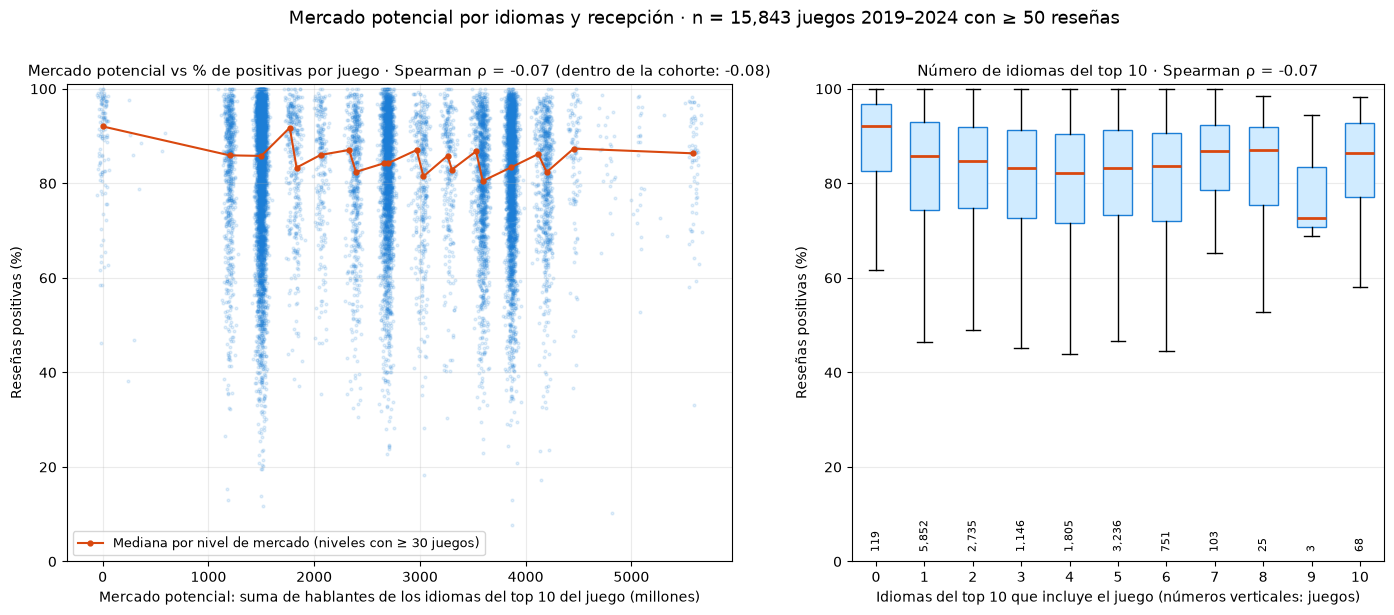

In [8]:
fig, (axScatter, axBox) = plt.subplots(1, 2, figsize=(17, 6.2), gridspec_kw={'wspace': 0.2, 'width_ratios': [1.25, 1]})
jitter = np.random.default_rng(randomSeed).normal(0, 25, len(sampleDf))
axScatter.scatter(sampleDf['idi_mercado_millones'] + jitter, sampleDf['positivePct'], s=4, alpha=0.12, color='#1C7ED6',
                  rasterized=True)
marketMedian = sampleDf.groupby('idi_mercado_millones')['positivePct'].agg(['median', 'size'])
marketMedian = marketMedian[marketMedian['size'] >= 30]
axScatter.plot(marketMedian.index, marketMedian['median'], color='#D9480F', marker='o', ms=3.5, lw=1.5,
               label='Mediana por nivel de mercado (niveles con ≥ 30 juegos)')
axScatter.set_xlabel('Mercado potencial: suma de hablantes de los idiomas del top 10 del juego (millones)')
axScatter.set_ylabel('Reseñas positivas (%)')
axScatter.set_ylim(0, 101)
axScatter.set_title(f'Mercado potencial vs % de positivas por juego · Spearman ρ = {rhoMarket:.2f} '
                    f'(dentro de la cohorte: {rhoMarketAdj:.2f})', fontsize=11)
axScatter.legend(fontsize=9, loc='lower left')
axScatter.grid(alpha=0.25)

boxData = [sampleDf.loc[sampleDf['idi_n_top10'] == k, 'positivePct'] for k in byCount['idi_n_top10']]
axBox.boxplot(boxData, positions=byCount['idi_n_top10'], widths=0.6, showfliers=False,
              medianprops=dict(color='#D9480F', lw=2), patch_artist=True,
              boxprops=dict(facecolor='#D0EBFF', edgecolor='#1C7ED6'))
for k, n in zip(byCount['idi_n_top10'], byCount['juegos']):
    axBox.text(k, 2, f'{n:,}', ha='center', fontsize=8, rotation=90, va='bottom')
axBox.set_xticks(byCount['idi_n_top10'])
axBox.set_xlabel('Idiomas del top 10 que incluye el juego (números verticales: juegos)')
axBox.set_ylabel('Reseñas positivas (%)')
axBox.set_ylim(0, 101)
axBox.set_title(f'Número de idiomas del top 10 · Spearman ρ = {rhoCount:.2f}', fontsize=11)
axBox.grid(axis='y', alpha=0.25)
fig.suptitle(f'Mercado potencial por idiomas y recepción · n = {len(sampleDf):,} juegos '
             f'{cohortRange[0]}–{cohortRange[1]} con ≥ {minReviews} reseñas', fontsize=13, y=1.0)
fig.savefig(figuresDir / '02g_idiomas_mercado.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. ¿El idioma se asocia con el éxito al controlar otros factores?

Los juegos con muchos idiomas suelen ser de estudios con más presupuesto, de otros géneros y de años recientes. Para separar el idioma de esos factores se ajustan regresiones lineales del porcentaje de positivas, con errores estándar robustos (HC3):

| Modelo | Variables |
|---|---|
| **A** | 10 indicadores de idioma + año de lanzamiento (efectos fijos) |
| **B** | A + precio, gratuito, Mac, Linux, 9 géneros y `idi_n_otros` (idiomas fuera del top 10) |
| **C** | Como B, pero con `idi_mercado_millones` (en cientos de millones) en lugar de los 10 indicadores |
| **Sin idiomas** | B sin los 10 indicadores; sirve para medir cuánto \(R^2\) aportan los idiomas |

Los coeficientes son **puntos porcentuales** de positivas: cuánto cambia el porcentaje cuando el juego incluye el idioma, con todo lo demás igual. Es una asociación, no un efecto causal.

In [9]:
controlTerms = ' + '.join(['logPrice', 'isFree', 'mac', 'linux'] + genreCols)
langTerms = ' + '.join(langCols)
sampleDf['mercadoCientos'] = sampleDf['idi_mercado_millones'] / 100
formulas = {
    'A': f'positivePct ~ {langTerms} + C(releaseYear)',
    'B': f'positivePct ~ {langTerms} + C(releaseYear) + {controlTerms} + idi_n_otros',
    'C': f'positivePct ~ mercadoCientos + C(releaseYear) + {controlTerms} + idi_n_otros',
    'Sin idiomas': f'positivePct ~ C(releaseYear) + {controlTerms} + idi_n_otros',
}
fits = {name: smf.ols(formula, data=sampleDf).fit(cov_type='HC3') for name, formula in formulas.items()}

coefRows = []
for modelName in ['A', 'B']:
    fit = fits[modelName]
    confInt = fit.conf_int()
    for colName in langCols:
        coefRows.append({'modelo': modelName, 'idioma': langNames[colName], 'coef': fit.params[colName],
                         'icBajo': confInt.loc[colName, 0], 'icAlto': confInt.loc[colName, 1],
                         'pValor': fit.pvalues[colName]})
coefDf = pd.DataFrame(coefRows)
coefDf.to_csv(metricsDir / '02g_idiomas_regresion.csv', index=False)

fitSummary = pd.DataFrame({name: {'R²': fit.rsquared, 'R² ajustado': fit.rsquared_adj, 'n': int(fit.nobs)}
                           for name, fit in fits.items()}).T
waldLang = fits['B'].wald_test(', '.join(f'{c} = 0' for c in langCols), scalar=True, use_f=True)   # prueba conjunta con errores HC3
print(f"Aporte de los 10 idiomas (B vs sin idiomas): ΔR² = {fits['B'].rsquared - fits['Sin idiomas'].rsquared:.4f}, "
      f"Wald F = {float(waldLang.statistic):.2f}, p = {float(waldLang.pvalue):.2g}")
print(f"Modelo C: +100 M de hablantes -> {fits['C'].params['mercadoCientos']:+.3f} pp "
      f"(IC 95 % {fits['C'].conf_int().loc['mercadoCientos', 0]:+.3f} a {fits['C'].conf_int().loc['mercadoCientos', 1]:+.3f}; "
      f"p = {fits['C'].pvalues['mercadoCientos']:.2g})")
print(f"Modelo B: cada idioma fuera del top 10 -> {fits['B'].params['idi_n_otros']:+.3f} pp "
      f"(p = {fits['B'].pvalues['idi_n_otros']:.2g})")
display(fitSummary.round(4))
coefDf.pivot(index='idioma', columns='modelo', values=['coef', 'pValor']).reindex([langNames[c] for c in langCols]).round(3)

Aporte de los 10 idiomas (B vs sin idiomas): ΔR² = 0.0094, Wald F = 16.96, p = 5e-31
Modelo C: +100 M de hablantes -> -0.122 pp (IC 95 % -0.146 a -0.099; p = 8.8e-24)
Modelo B: cada idioma fuera del top 10 -> +0.122 pp (p = 0.0054)


,R²,R² ajustado,n
A,0.0186,0.0177,15843.0
B,0.1035,0.1019,15843.0
C,0.0997,0.0986,15843.0
Sin idiomas,0.0942,0.0931,15843.0


coef        pValor       
modelo              A      B      A      B
idioma                                    
Inglés         -0.784 -1.635  0.160  0.002
Chino mandarín -1.137 -1.313  0.000  0.000
Hindi           1.297  2.388  0.389  0.090
Español         0.085 -0.487  0.841  0.233
Árabe estándar -0.661 -1.580  0.221  0.007
Francés        -2.788 -2.698  0.000  0.000
Bengalí         0.581 -5.528  0.885  0.184
Portugués       1.982  1.475  0.000  0.000
Indonesio       1.352  0.919  0.095  0.241
Urdu            1.371 -3.334  0.721  0.436

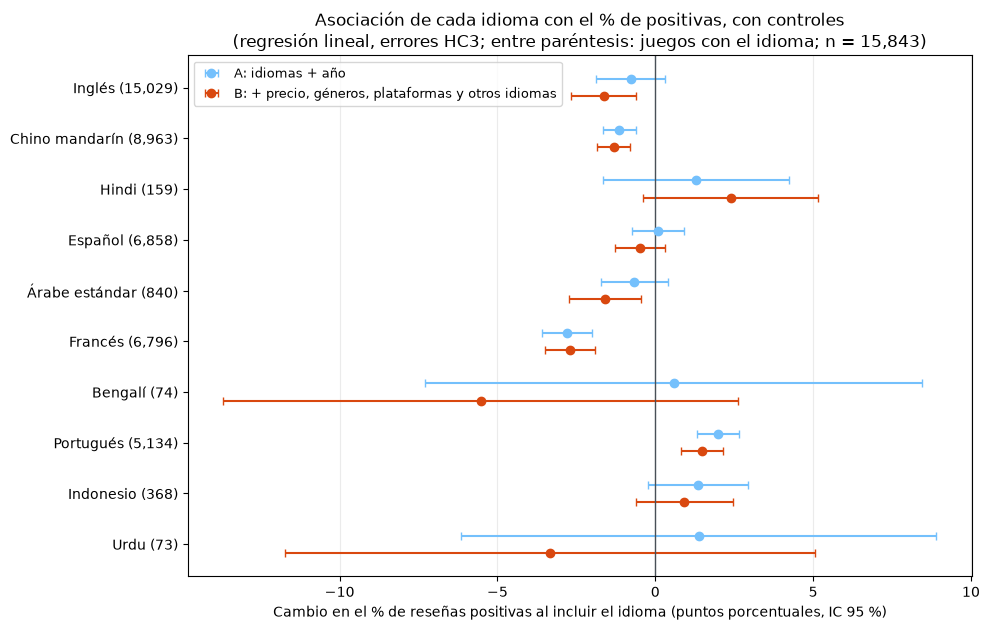

In [10]:
fig, ax = plt.subplots(figsize=(10, 6.4))
order = [langNames[c] for c in langCols][::-1]
yBase = np.arange(len(order))
for offset, modelName, colorName, label in [(0.17, 'A', '#74C0FC', 'A: idiomas + año'),
                                            (-0.17, 'B', '#D9480F', 'B: + precio, géneros, plataformas y otros idiomas')]:
    sub = coefDf[coefDf['modelo'] == modelName].set_index('idioma').reindex(order)
    ax.errorbar(sub['coef'], yBase + offset, xerr=[sub['coef'] - sub['icBajo'], sub['icAlto'] - sub['coef']],
                fmt='o', color=colorName, ecolor=colorName, capsize=3, ms=6, label=label)
ax.axvline(0, color='#495057', lw=1)
ax.set_yticks(yBase)
ax.set_yticklabels([f"{name} ({int(langStats.set_index('idioma').loc[name, 'juegosCon']):,})" for name in order])
ax.set_xlabel('Cambio en el % de reseñas positivas al incluir el idioma (puntos porcentuales, IC 95 %)')
ax.set_title(f'Asociación de cada idioma con el % de positivas, con controles\n'
             f'(regresión lineal, errores HC3; entre paréntesis: juegos con el idioma; n = {len(sampleDf):,})', fontsize=12)
ax.legend(fontsize=9, loc='upper left')
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
fig.savefig(figuresDir / '02g_idiomas_regresion.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Robustez

Se repiten la correlación del mercado potencial y el modelo B con otras muestras: todas las cohortes 2014–2024 y umbrales de 10 y 100 reseñas.

In [11]:
baseMask = (~onlySoftware & ~nonGameName & (gamesDf['price'].fillna(0) < 1000)
            & (gamesDf['steam_store_available'].astype(str) == 'True') & ~idiomasDf['idi_sin_dato'].to_numpy())
robustRows = []
for (yearLow, yearHigh), reviewsMin in [((2019, 2024), 50), ((2014, 2024), 50), ((2019, 2024), 10), ((2019, 2024), 100)]:
    mask = baseMask & gamesDf['releaseYear'].between(yearLow, yearHigh) & (gamesDf['reviewCount'] >= reviewsMin)
    subDf = controlDf[mask].merge(idiomasDf.reset_index(), on='app_id', how='left')
    subDf['releaseYear'] = subDf['releaseYear'].astype(int)
    subDf[langCols] = subDf[langCols].astype(int)
    fitB = smf.ols(formulas['B'], data=subDf).fit(cov_type='HC3')
    fitNo = smf.ols(formulas['Sin idiomas'], data=subDf).fit(cov_type='HC3')
    residual = subDf['positivePct'] - subDf.groupby('releaseYear')['positivePct'].transform('mean')
    row = {'muestra': f'{yearLow}–{yearHigh}, ≥ {reviewsMin}', 'juegos': len(subDf),
           'rhoMercado': spearmanr(subDf['idi_mercado_millones'], subDf['positivePct']).statistic,
           'rhoMercadoCohorte': spearmanr(subDf['idi_mercado_millones'], residual).statistic,
           'deltaR2Idiomas': fitB.rsquared - fitNo.rsquared,
           'pIdiomas': float(fitB.wald_test(', '.join(f'{c} = 0' for c in langCols), scalar=True, use_f=True).pvalue)}
    for colName in ['idi_tiene_ingles', 'idi_tiene_chino', 'idi_tiene_espanol', 'idi_tiene_frances',
                    'idi_tiene_portugues', 'idi_tiene_arabe']:
        row[f'coefB_{colName.replace("idi_tiene_", "")}'] = fitB.params[colName]
    robustRows.append(row)
robustDf = pd.DataFrame(robustRows)
robustDf.to_csv(metricsDir / '02g_idiomas_robustez.csv', index=False)
robustDf.round(3)

,muestra,juegos,rhoMercado,rhoMercadoCohorte,deltaR2Idiomas,pIdiomas,coefB_ingles,coefB_chino,coefB_espanol,coefB_frances,coefB_portugues,coefB_arabe
0,"2019–2024, ≥ 50",15843,-0.069,-0.083,0.009,0.0,-1.635,-1.313,-0.487,-2.698,1.475,-1.580
1,"2014–2024, ≥ 50",26956,0.060,0.005,0.004,0.0,-2.213,0.197,-0.307,-2.226,1.704,-2.357
2,"2019–2024, ≥ 10",33438,-0.030,-0.047,0.004,0.0,-0.530,-0.586,1.114,-1.731,2.075,-1.238
3,"2019–2024, ≥ 100",11399,-0.099,-0.107,0.014,0.0,-1.381,-1.637,-0.698,-3.010,1.241,-1.935


## Conclusiones del notebook

Cifras de la ejecución con la versión del 2026-11-19, sobre 15,843 juegos de 2019–2024 con ≥ 50 reseñas y una media de 81.3 % de positivas.

**Cobertura**

- En la muestra, 94.9 % de los juegos incluye inglés, 56.6 % chino, 43.3 % español, 42.9 % francés y 32.4 % portugués. Árabe (5.3 %), indonesio (2.3 %), hindi (1.0 %), bengalí (0.5 %) y urdu (0.5 %) son raros. Hindi, bengalí y urdu aparecen sobre todo en los 68 juegos que incluyen los 10 idiomas.

**¿El idioma afecta el porcentaje de positivas?**

- **Muy poco.** Las diferencias entre juegos con y sin cada idioma van de −2.1 a +3.1 puntos porcentuales, frente a una desviación estándar entre juegos de unos 14 puntos. Dentro de la cohorte, francés (−2.1), chino (−1.8), español (−1.6) y portugués (−0.5) tienen diferencias negativas con un IC 95 % que no cruza el cero. Urdu y bengalí salen positivos (+3.1), pero con unos 73 juegos cada uno y un intervalo muy amplio.
- **Más mercado potencial no significa mejor recepción.** La correlación de Spearman entre los hablantes cubiertos y el porcentaje de positivas es −0.07 (−0.08 dentro de la cohorte). Con controles, cada 100 millones de hablantes adicionales se asocian con −0.12 puntos.
- **El mercado potencial sí se relaciona con el alcance.** Su correlación con el volumen de reseñas, dentro de la cohorte, es +0.31. Los juegos con más idiomas llegan a más jugadores, pero no reciben una proporción mayor de reseñas positivas. Una hipótesis, no probada aquí: un público más amplio y diverso es más exigente o critica la calidad de la traducción.
- **Con controles, los idiomas aportan poco:** el \\(R^2\\) sube de 0.094 a 0.104 (Δ = 0.009). La prueba conjunta es significativa (Wald F = 17, p < 0.001) por el tamaño de la muestra, no por la magnitud del efecto.
- **Coeficientes estables en las cuatro muestras de robustez:** portugués de +1.2 a +2.1 puntos, francés de −1.7 a −3.0 y árabe de −1.2 a −2.4. El chino y el español **cambian de signo** según la muestra, así que no hay conclusión firme para ellos. El inglés sale negativo, pero se compara contra solo 5 % de juegos sin inglés, en su mayoría dirigidos a mercados asiáticos.

**Propuesta para el modelo (A-007, S1-06)**

- Para predecir la **recepción** (D-003), los idiomas son variables de bajo peso. Conviene incluir los indicadores más frecuentes (inglés, chino, español, francés, portugués) y `idi_n_otros`, y no esperar que expliquen mucho.
- `idi_mercado_millones` **no** sirve como medida de éxito en recepción. Sí podría servir en un análisis de alcance (volumen de reseñas o propietarios estimados), si el equipo lo retoma.
- Hindi, bengalí y urdu tienen muy pocos juegos para estimar algo por separado; se pueden agrupar en `idi_n_top10`.
- El ruso quedó fuera del top 10 de Ethnologue 2026, pero lo incluye el 39 % de los juegos de la muestra (columna de la especificación de S1-06). Para agregarlo basta añadir una entrada a `TOP10_IDIOMAS` en el programa.

**Limitaciones**

- `supported_languages` es el valor actual de la tienda. Un juego exitoso puede agregar idiomas después del lanzamiento, y eso infla la relación con el alcance.
- La suma de hablantes cuenta dos veces a las personas bilingües, y no distingue la traducción de texto del doblaje.
- Son asociaciones, no efectos causales.